# Windy Gridworld

In [2]:
wind = [0, 0, 0, 1, 1, 1, 2, 2, 1, 0]    # cells pushed up, per column
height = 7
start, goal = (0, 3), (7, 3)             # (x, y), y=0 is the top row

<Axes: title={'center': 'Windy gridworld'}>

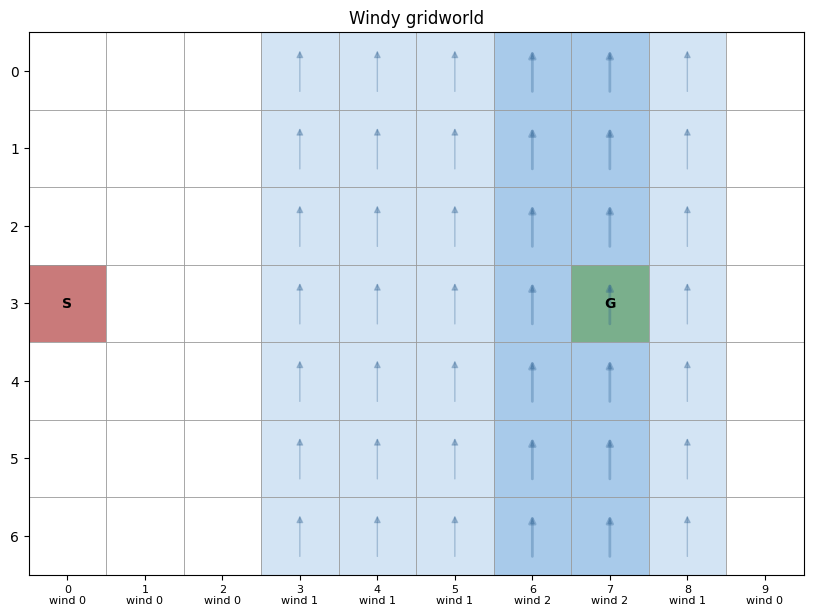

In [3]:
from draw import draw_windy_gridworld
draw_windy_gridworld(title="Windy gridworld", wind=wind, height=height, start=start, goal=goal)

In [4]:
# Gym environment 

In [5]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np

In [6]:
def get_actions(mode=4):
        """4 = standard, 8 = King's moves, 9 = King's moves + stay."""
        if mode not in (4, 8, 9):
            raise ValueError("mode must be 4, 8 or 9")
        actions = {"up": (0, -1), "down": (0, 1), "left": (-1, 0), "right": (1, 0)}
        if mode >= 8:
            actions.update({"up-left": (-1, -1), "up-right": (1, -1),
                            "down-left": (-1, 1), "down-right": (1, 1)})
        if mode == 9:
            actions["stay"] = (0, 0)
        return list(actions), list(actions.values())

In [7]:
class WindyGridworldEnv(gym.Env):
    def __init__(self, wind, height, start, goal, action_mode = 4, stochastic= False, max_steps = np.inf):
        super().__init__()
        self.wind = wind
        self.start = start
        self.goal = goal
        self.height = height
        self.max_steps = max_steps
        self.width = len(wind)
        self.action_mode = action_mode
        self.stochastic = stochastic
        self.action_names, self.moves = get_actions(action_mode)
        self.action_space = spaces.Discrete(len(self.moves))
        self.observation_space =spaces.MultiDiscrete([self.width, self.height])
        self.step_count = 0
        
    def reset(self, *, seed = None, options = None):
        super().reset(seed=seed)
        self.state = np.array(self.start, dtype=np.int32)
        self.step_count = 0
        return self.state.copy(), {}
    
    def step(self, action):
        x, y = map(int, self.state)
        dx, dy = self.moves[action]
        wind = self._wind_at(x)
        
        new_x = int(np.clip(x+dx, 0, self.width -1))
        new_y = int(np.clip(y +dy - wind, 0, self.height -1))
        
        self.state = np.array([new_x, new_y], dtype=np.int32)
        self.step_count += 1
        
        terminated = (new_x, new_y) == tuple(self.goal)
        truncated = self.step_count >= self.max_steps
        return self.state.copy(), -1, terminated, truncated, {}
         
# helpers

    
    def _wind_at(self, x):
        w = self.wind[x]
        if self.stochastic and w>0:
            w += int(self.np_random.integers(-1,2))
        return w
            
    

In [8]:
# SARSA

In [9]:
lr = 0.5
def to_state(obs):
    return  tuple(int(v) for v in obs)

def make_Q(env):
    return np.zeros((env.width, env.height, env.action_space.n))
def epsilon_greedy(Q, state, epsilon, rng):
    x, y = state
    if rng.random() < epsilon:
        return int(rng.integers(Q.shape[-1]))
    q = Q[x,y]
    return int(rng.choice(np.flatnonzero(q==q.max())))

def sarsa_update(Q, s, a, r, s2, a2, lr, gamma, terminated):
    if terminated:
        target = r
    else: 
        target = r + gamma* Q[s2 + (a2,)]
    td_error = target - Q[s  + (a,)]
    Q[s + (a,)] += lr* td_error
    return td_error


In [10]:
def run_sarsa(env, n_steps = 8000, lr = 0.5, epsilon=0.1, gamma = 1.0, seed = 42):
    rng = np.random.default_rng(seed=seed)
    Q = make_Q(env)
    episode_ends = []
    t = 0
    first = True
    
    while t< n_steps:
        obs, _ = env.reset(seed=seed if first else None)
        first = False
        s = to_state(obs)
        a = epsilon_greedy(Q, s, epsilon, rng)
        
        while t < n_steps:
            obs, r, terminated, truncated, _ = env.step(a)
            s2 = to_state(obs)
            t += 1
            a2 = epsilon_greedy(Q, s2, epsilon, rng)
            sarsa_update(Q, s, a, r, s2, a2, lr, gamma, terminated)
            s, a = s2, a2
            
            if terminated or truncated:
                episode_ends.append(t)
                break
    return Q, episode_ends

            

In [11]:
import matplotlib.pyplot as plt


episodes: 170
Q entries learned: 248


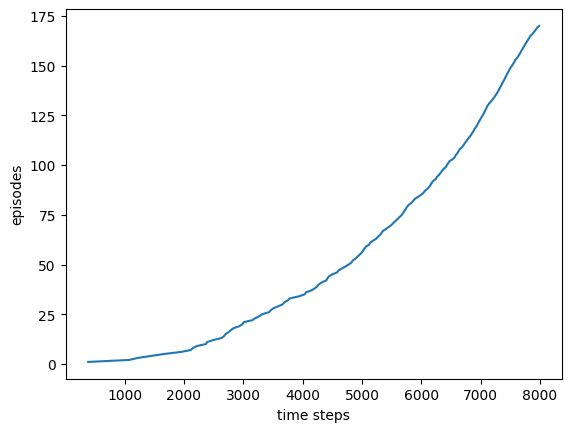

In [12]:
env = WindyGridworldEnv(wind, height, start, goal, action_mode=4)
Q, ends = run_sarsa(env)

print("episodes:", len(ends))
print("Q entries learned:", (Q != 0).sum())
plt.plot(ends, np.arange(1, len(ends) + 1))
plt.xlabel("time steps"); plt.ylabel("episodes"); plt.show()

reached goal: False  steps: 100


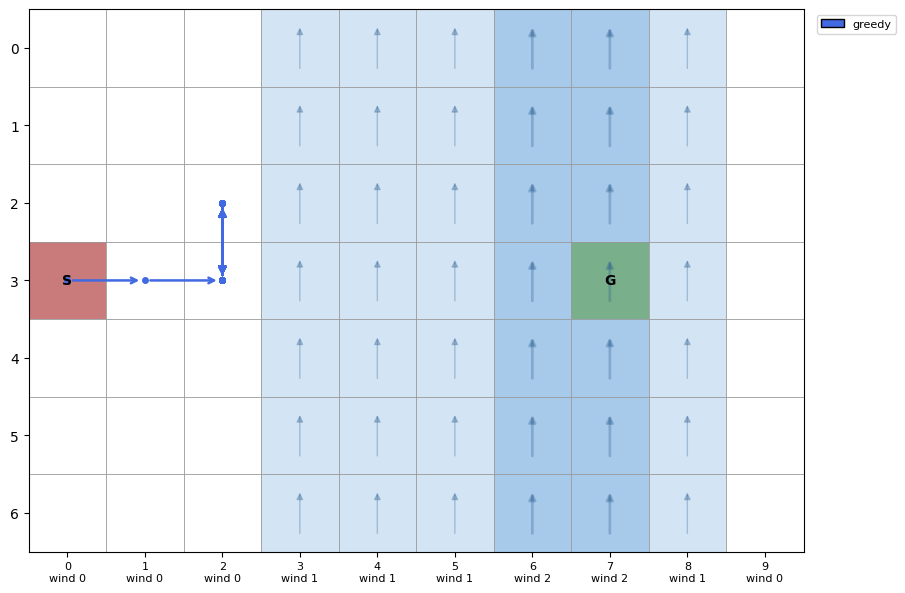

In [13]:
def greedy_path(env, Q, max_steps=100):
    obs, _ = env.reset()
    path = [to_state(obs)]
    reached = False
    for _ in range(max_steps):
        x, y = path[-1]
        obs, _, terminated, truncated, _ = env.step(int(np.argmax(Q[x, y])))
        path.append(to_state(obs))
        if terminated:
            reached = True
        if terminated or truncated:
            break
    return path, reached

path, reached = greedy_path(env, Q)
print("reached goal:", reached, " steps:", len(path) - 1)
draw_windy_gridworld(wind, height, start, goal, paths={"greedy": (path, "royalblue")})
plt.show()

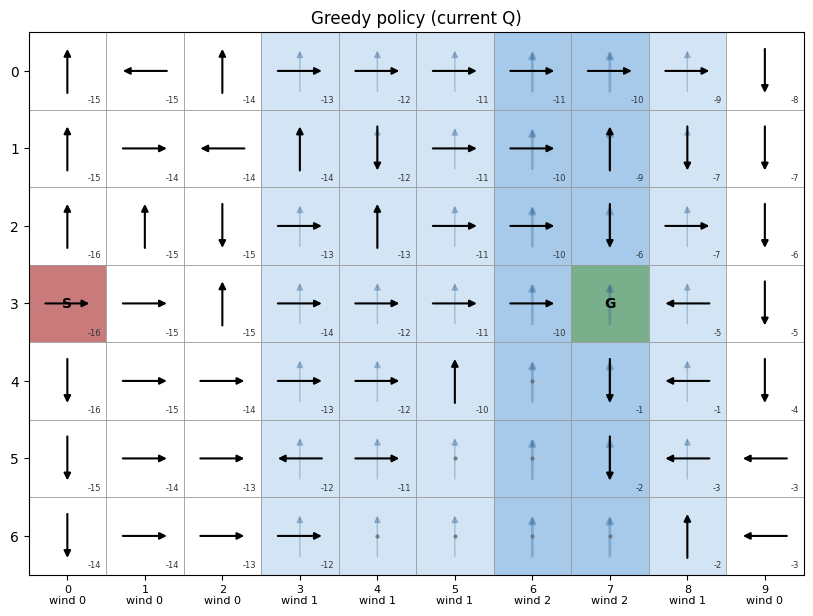

In [14]:
from draw import draw_greedy_policy_windygrid
draw_greedy_policy_windygrid(Q, env.moves, wind, height, start, goal,
                   title="Greedy policy (current Q)")
plt.show()

In [15]:
# solved via SARSA the 8000 episode give the wrong greedy for some reason but increasing n_steps give the cleaner path

In [16]:
## Ablation for action set = 4, 8, 9 actions 
n_steps = 100000

episodes: 5003
Q entries learned: 248


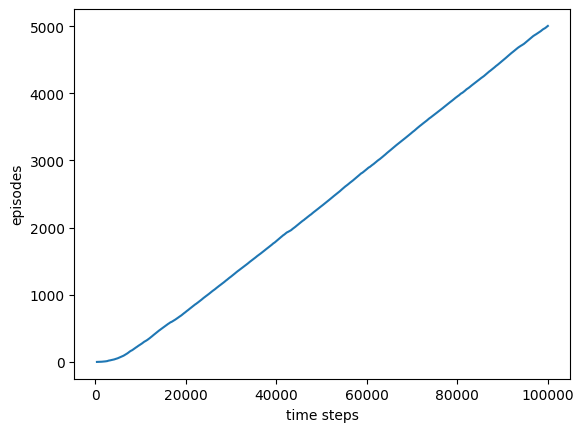

In [17]:
## mode = 4
env = WindyGridworldEnv(wind, height, start, goal, action_mode=4)
Q, ends = run_sarsa(env, n_steps=n_steps)

print("episodes:", len(ends))
print("Q entries learned:", (Q != 0).sum())
plt.plot(ends, np.arange(1, len(ends) + 1))
plt.xlabel("time steps"); plt.ylabel("episodes"); plt.show()

reached goal: True  steps: 15


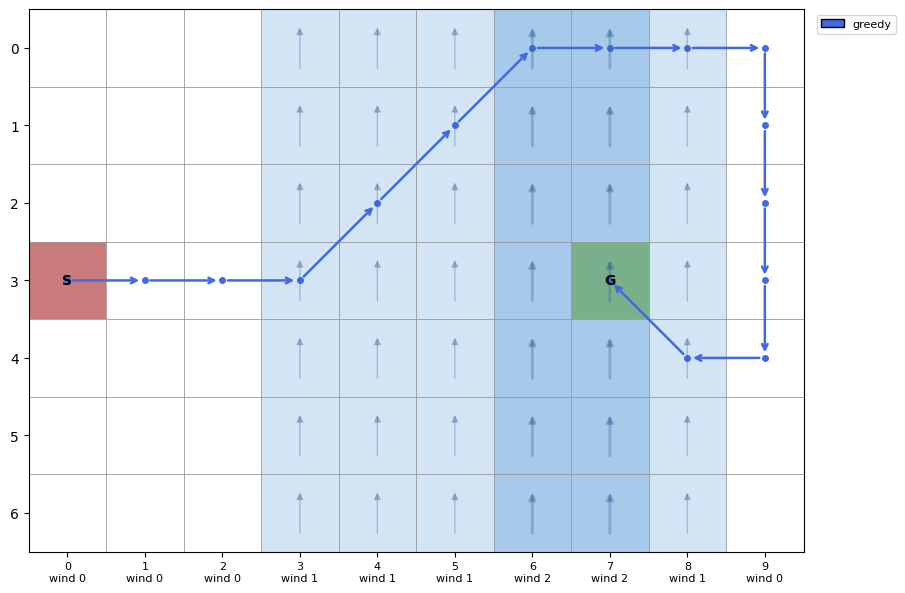

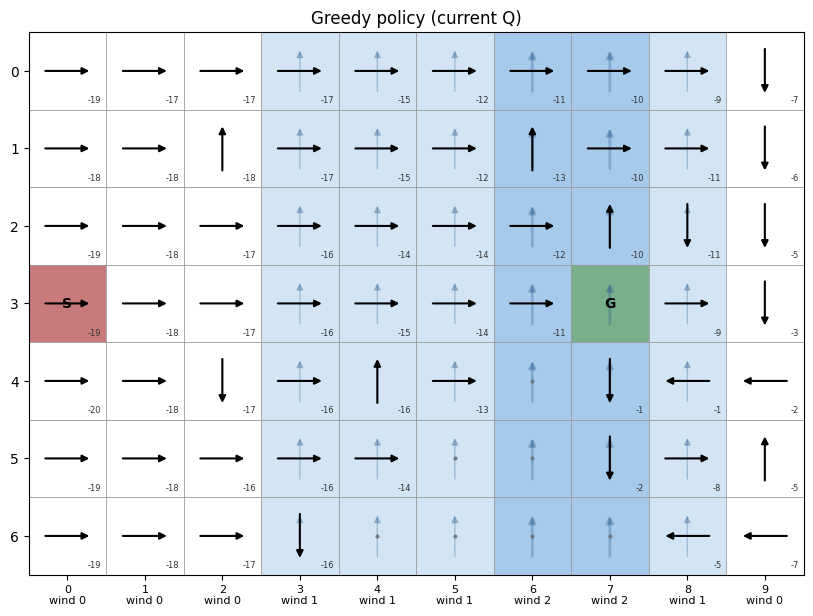

In [18]:
path, reached = greedy_path(env, Q)
print("reached goal:", reached, " steps:", len(path) - 1)
draw_windy_gridworld(wind, height, start, goal, paths={"greedy": (path, "royalblue")})
plt.show()

draw_greedy_policy_windygrid(Q, env.moves, wind, height, start, goal,
                   title="Greedy policy (current Q)")
plt.show()

episodes: 8895
Q entries learned: 552


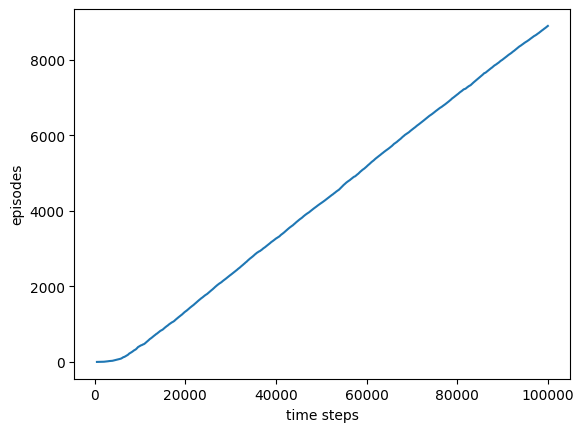

In [19]:
## mode = 8
env = WindyGridworldEnv(wind, height, start, goal, action_mode=8)
Q, ends = run_sarsa(env, n_steps=n_steps)

print("episodes:", len(ends))
print("Q entries learned:", (Q != 0).sum())
plt.plot(ends, np.arange(1, len(ends) + 1))
plt.xlabel("time steps"); plt.ylabel("episodes"); plt.show()

reached goal: True  steps: 8


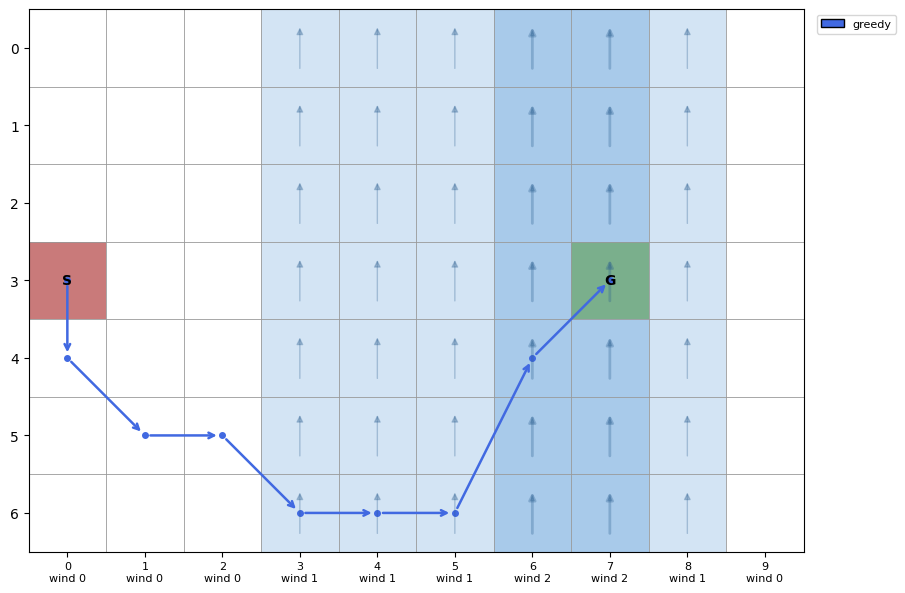

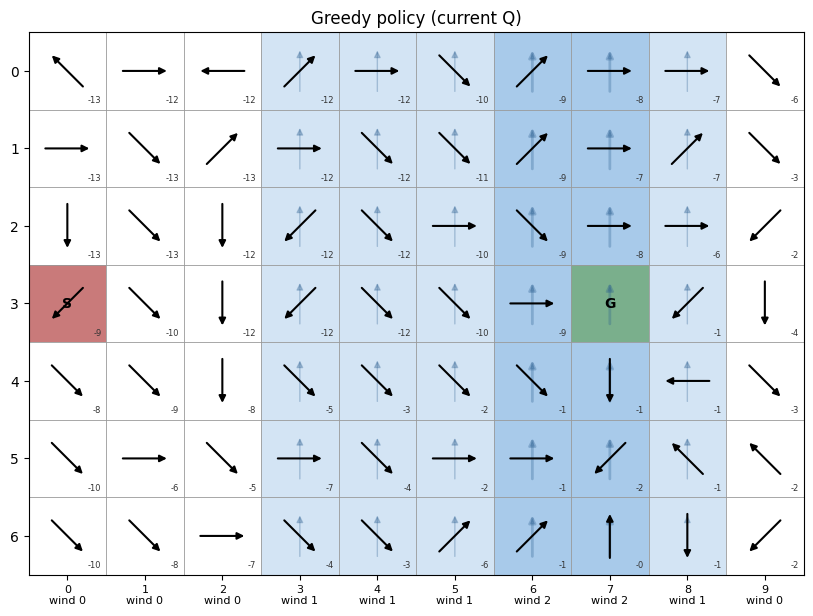

In [20]:
path, reached = greedy_path(env, Q)
print("reached goal:", reached, " steps:", len(path) - 1)
draw_windy_gridworld(wind, height, start, goal, paths={"greedy": (path, "royalblue")})
plt.show()

draw_greedy_policy_windygrid(Q, env.moves, wind, height, start, goal,
                   title="Greedy policy (current Q)")
plt.show()

episodes: 8777
Q entries learned: 621


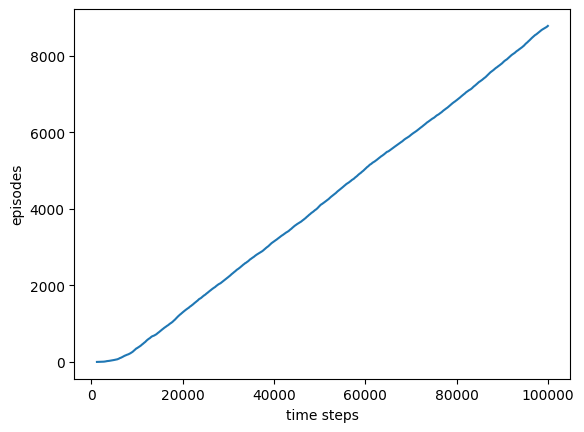

In [21]:
## mode = 9
env = WindyGridworldEnv(wind, height, start, goal, action_mode=9)
Q, ends = run_sarsa(env, n_steps=n_steps)

print("episodes:", len(ends))
print("Q entries learned:", (Q != 0).sum())
plt.plot(ends, np.arange(1, len(ends) + 1))
plt.xlabel("time steps"); plt.ylabel("episodes"); plt.show()

reached goal: True  steps: 8


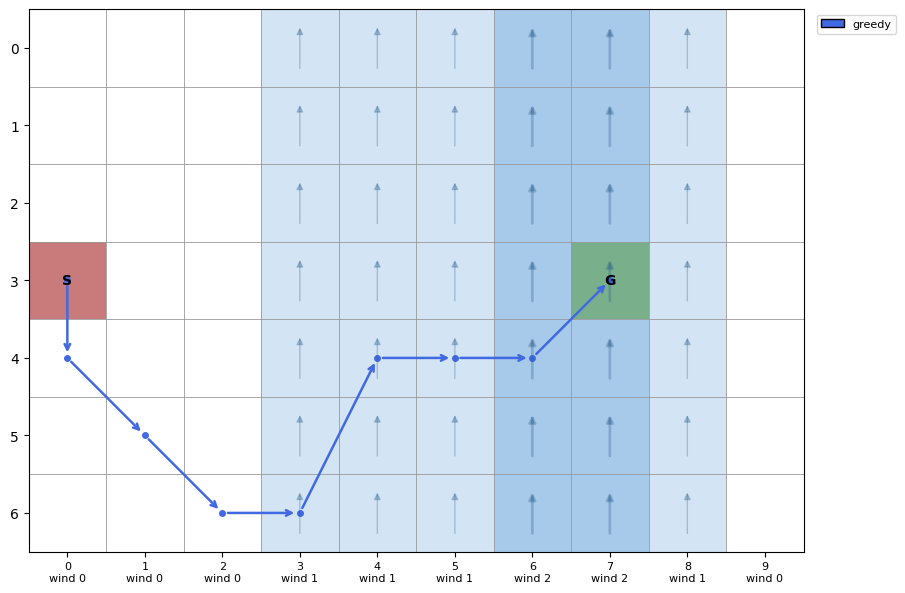

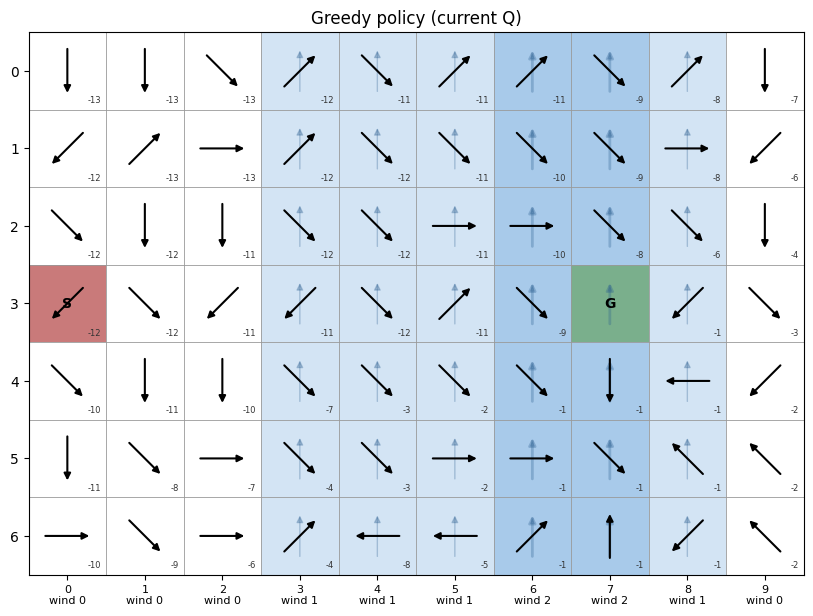

In [22]:
path, reached = greedy_path(env, Q)
print("reached goal:", reached, " steps:", len(path) - 1)
draw_windy_gridworld(wind, height, start, goal, paths={"greedy": (path, "royalblue")})
plt.show()

draw_greedy_policy_windygrid(Q, env.moves, wind, height, start, goal,
                   title="Greedy policy (current Q)")
plt.show()

In [23]:
## Stochasticity = True

In [27]:
env = WindyGridworldEnv(wind, height, start, goal, action_mode=8, stochastic=True)
Q, ends = run_sarsa(env, n_steps=50000, lr=0.5)

The 8 action sets learnt different policy at 20k steps and 50k steps, the 20k steps is similar to that of 4 action mode and 50k is similar to 8 action policy which is pretty interesting

episodes: 959
Q entries learned: 552


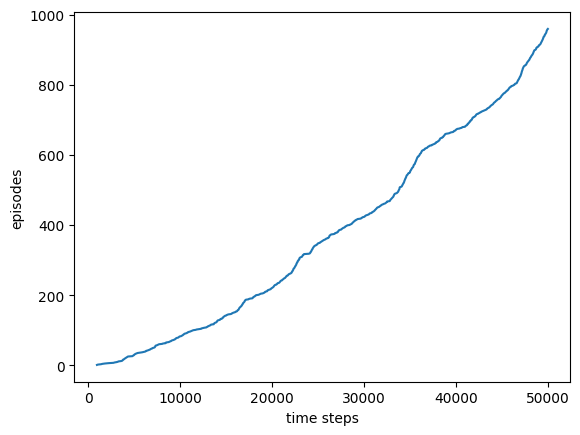

In [28]:

print("episodes:", len(ends))
print("Q entries learned:", (Q != 0).sum())
plt.plot(ends, np.arange(1, len(ends) + 1))
plt.xlabel("time steps"); plt.ylabel("episodes"); plt.show()

reached goal: True  steps: 8


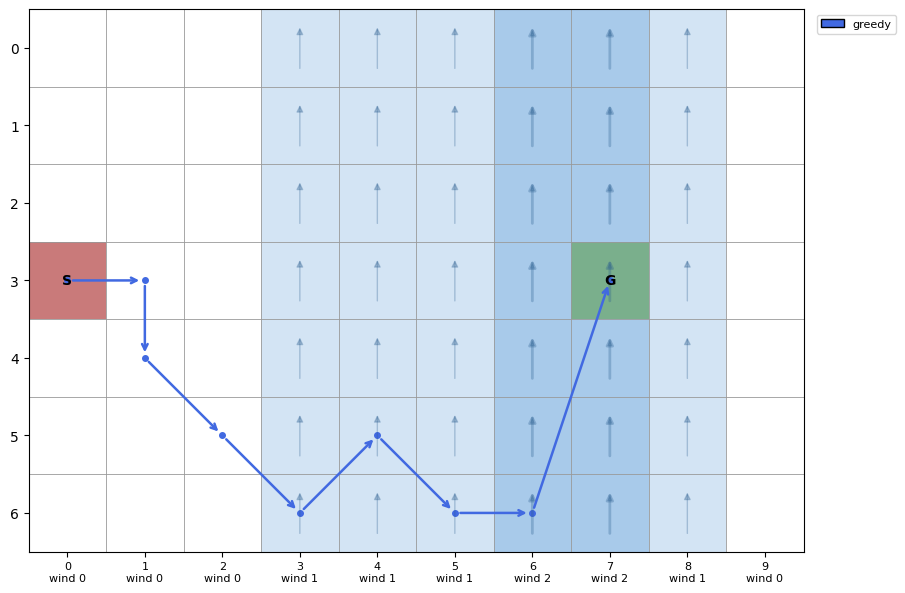

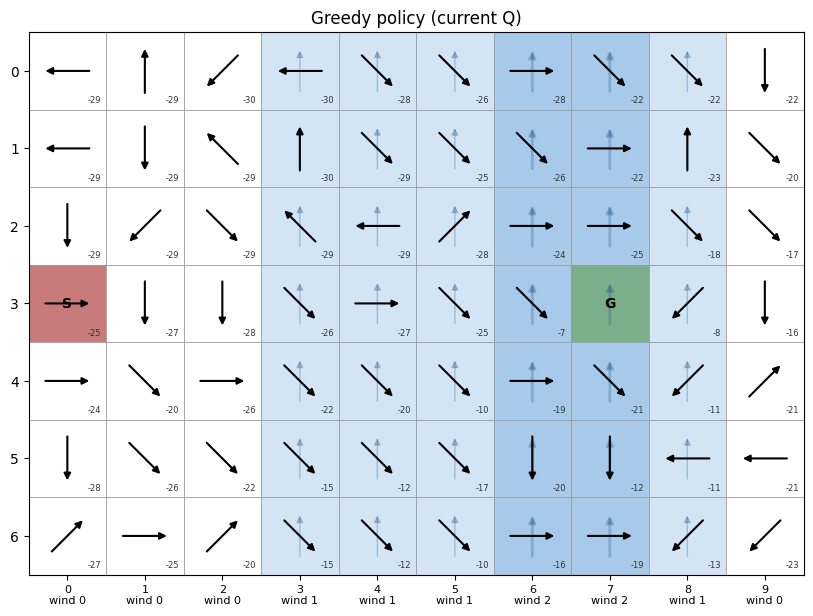

In [29]:
path, reached = greedy_path(env, Q)
print("reached goal:", reached, " steps:", len(path) - 1)
draw_windy_gridworld(wind, height, start, goal, paths={"greedy": (path, "royalblue")})
plt.show()

draw_greedy_policy_windygrid(Q, env.moves, wind, height, start, goal,
                   title="Greedy policy (current Q)")
plt.show()